**EDA**

In [59]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [60]:
data = pd.read_csv('insurance.csv')

In [61]:
data

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86
...,...,...,...,...,...,...,...
1333,50,male,31.0,3,no,northwest,10600.55
1334,18,female,31.9,0,no,northeast,2205.98
1335,18,female,36.9,0,no,southeast,1629.83
1336,21,female,25.8,0,no,southwest,2007.95


In [62]:
data.shape

(1338, 7)

In [63]:
data.head()

,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [64]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [65]:
data.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
expenses,0


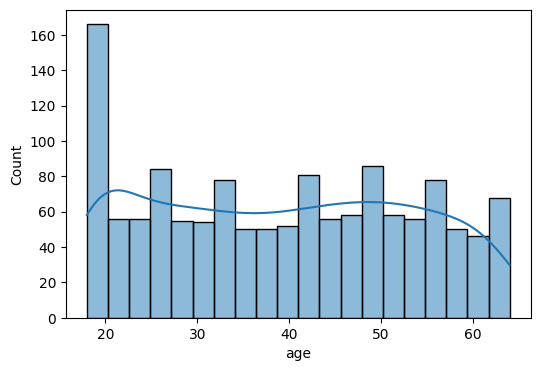

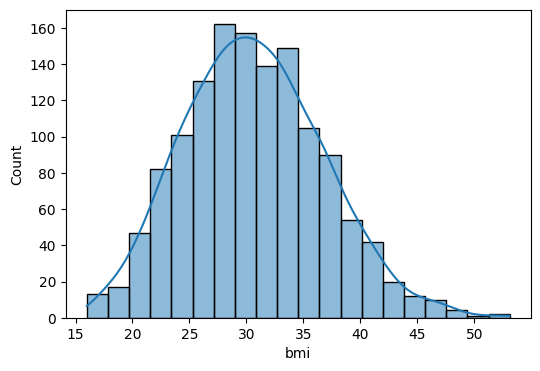

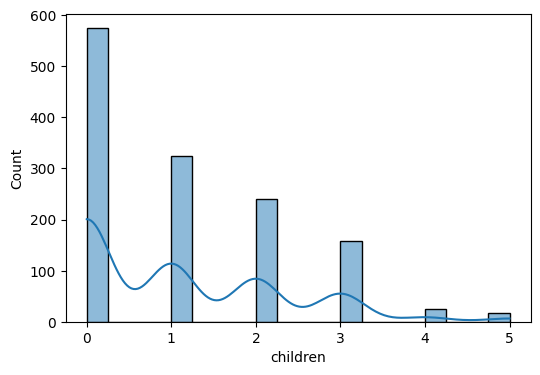

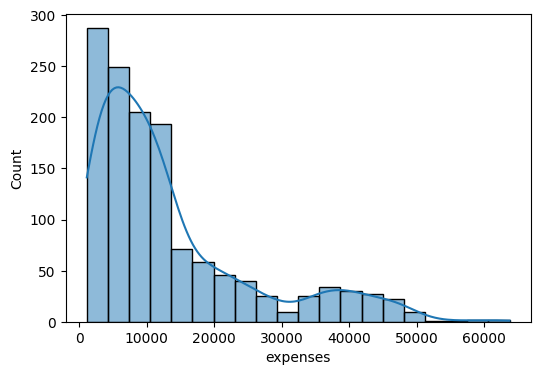

In [66]:
numeric_columns=['age','bmi','children','expenses']
for col in numeric_columns:
  plt.figure(figsize=(6,4))
  sns.histplot(data[col],kde=True,bins=20)

In [67]:
data['sex']=data['sex'].map({'male': 0,'female':1})

In [68]:
data['sex']

,sex
0,1
1,0
2,0
3,0
4,0
...,...
1333,0
1334,1
1335,1
1336,1


In [69]:
data['smoker'] = data['smoker'].map({'yes':0,'no':1})

In [70]:
data['bmi_category'] = pd.cut(
    data['bmi'],
    bins=[0, 18.5, 25, 30, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese'],
    right=False
)

In [71]:
data[['bmi', 'bmi_category']].head()


,bmi,bmi_category
0,27.9,Overweight
1,33.8,Obese
2,33.0,Obese
3,22.7,Normal
4,28.9,Overweight


In [72]:
data=pd.get_dummies(data,columns=['bmi_category'],drop_first=True)

In [73]:
data.head()

,age,sex,bmi,children,smoker,region,expenses,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27.9,0,0,southwest,16884.92,False,True,False
1,18,0,33.8,1,1,southeast,1725.55,False,False,True
2,28,0,33.0,3,1,southeast,4449.46,False,False,True
3,33,0,22.7,0,1,northwest,21984.47,True,False,False
4,32,0,28.9,0,1,northwest,3866.86,False,True,False


In [74]:
data=pd.get_dummies(data,columns=['region'],drop_first=True)

In [75]:
data.head()

,age,sex,bmi,children,smoker,expenses,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,region_northwest,region_southeast,region_southwest
0,19,1,27.9,0,0,16884.92,False,True,False,False,False,True
1,18,0,33.8,1,1,1725.55,False,False,True,False,True,False
2,28,0,33.0,3,1,4449.46,False,False,True,False,True,False
3,33,0,22.7,0,1,21984.47,True,False,False,True,False,False
4,32,0,28.9,0,1,3866.86,False,True,False,True,False,False


In [76]:
data.astype(int)

,age,sex,bmi,children,smoker,expenses,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,region_northwest,region_southeast,region_southwest
0,19,1,27,0,0,16884,0,1,0,0,0,1
1,18,0,33,1,1,1725,0,0,1,0,1,0
2,28,0,33,3,1,4449,0,0,1,0,1,0
3,33,0,22,0,1,21984,1,0,0,1,0,0
4,32,0,28,0,1,3866,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,31,3,1,10600,0,0,1,1,0,0
1334,18,1,31,0,1,2205,0,0,1,0,0,0
1335,18,1,36,0,1,1629,0,0,1,0,1,0
1336,21,1,25,0,1,2007,0,1,0,0,0,1


In [77]:
import sklearn
from sklearn.preprocessing import StandardScaler
Scalar = StandardScaler()
cols=['bmi','age','children']
data[cols]= Scalar.fit_transform(data[cols])

In [32]:
data.head()

,age,sex,bmi,children,smoker,expenses,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,region_northwest,region_southeast,region_southwest
0,-1.438764,1,-0.453646,-0.908614,0,16884.92,False,True,False,False,False,True
1,-1.509965,0,0.514186,-0.078767,1,1725.55,False,False,True,False,True,False
2,-0.797954,0,0.382954,1.580926,1,4449.46,False,False,True,False,True,False
3,-0.441948,0,-1.306650,-0.908614,1,21984.47,True,False,False,True,False,False
4,-0.513149,0,-0.289606,-0.908614,1,3866.86,False,True,False,True,False,False


In [78]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'expenses',
       'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese',
       'region_northwest', 'region_southeast', 'region_southwest'],
      dtype='object')

In [83]:
data[['bmi_category_Normal','bmi_category_Overweight','bmi_category_Obese','region_northwest','region_southeast','region_southwest']]=data[['bmi_category_Normal','bmi_category_Overweight','bmi_category_Obese','region_northwest','region_southeast','region_southwest']].astype(int)

In [84]:
data

,age,sex,bmi,children,smoker,expenses,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,region_northwest,region_southeast,region_southwest
0,-1.438764,1,-0.453646,-0.908614,0,16884.92,0,1,0,0,0,1
1,-1.509965,0,0.514186,-0.078767,1,1725.55,0,0,1,0,1,0
2,-0.797954,0,0.382954,1.580926,1,4449.46,0,0,1,0,1,0
3,-0.441948,0,-1.306650,-0.908614,1,21984.47,1,0,0,1,0,0
4,-0.513149,0,-0.289606,-0.908614,1,3866.86,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.768473,0,0.054876,1.580926,1,10600.55,0,0,1,1,0,0
1334,-1.509965,1,0.202511,-0.908614,1,2205.98,0,0,1,0,0,0
1335,-1.509965,1,1.022707,-0.908614,1,1629.83,0,0,1,0,1,0
1336,-1.296362,1,-0.798128,-0.908614,1,2007.95,0,1,0,0,0,1
